# Benchmark: 24 real regression data sets

This study compares default prediction workflows on 24 development data sets
from OpenML-CTR23. Each method receives the same training/test split. The
mboostrs default is `autospec(budget=200)` followed by `rec.fit`; its pair,
residual-tree, REML-refit and stronger-deselection variants are separate
methods. Their best test score is never substituted for the default policy.

The target is prediction for new rows from each sampled population. The
sampling unit is one row, and splits also hold out rows; this random-split design does not establish
performance on future periods, unseen clusters or another population. The
estimand is test R², which is unitless, on each data set. Training and test
parts are capped at 5,000 rows; five 80/20 splits repeat the workflow. Tuning
uses only the training rows. Uncertainty from the five overlapping splits is summarized descriptively;
these repetitions do not support an independent-sample significance test.

These are development tasks used to motivate the specification policy. The
14 reserved confirmation tasks (held back to test the policy after it is fixed) are not part of this artifact, and no claim
that the proposed default wins on confirmation data is made here.

## Comparison across methods

The headline compares every method on the same set of data sets with all five
splits successful for every method. Failed fits are counted over the full
planned study and detailed below. R² is first averaged within each data set;
then its median and mean summarize those common data sets. A negative R² is
retained and means the prediction is worse than the test-set mean reference.


In [1]:
import json
from pathlib import Path

import altair as alt
import polars as pl
from IPython.display import display

from bench_tables import table

alt.renderers.enable("svg")
bench = json.loads(Path("bench_realdata_preexploration.json").read_text())
PRIMARY = "mboostrs autospec"
rows = [{"dataset": r.get("dataset", str(r["data_id"])), "method": r["method"],
         "seed": r["seed"], "r2": r.get("r2"), "seconds": r.get("seconds"),
         "status": r.get("_status", "unknown"), "error": r.get("error", str(r.get("failure", "")))}
        for r in bench["results"]]
frame = pl.DataFrame(rows, infer_schema_length=None)


In [2]:
# A common complete-data-set set prevents failures from changing the scoring population by method.
success = frame.filter((pl.col("status") == "success") & pl.col("r2").is_finite())
per_data = success.group_by("dataset", "method").agg(
    pl.len().alias("splits"), pl.col("r2").mean(), pl.col("seconds").median())
method_count = frame["method"].n_unique()
common = (per_data.filter(pl.col("splits") == 5).group_by("dataset")
          .agg(pl.col("method").n_unique().alias("methods"))
          .filter(pl.col("methods") == method_count)["dataset"].to_list())
matched = per_data.filter(pl.col("dataset").is_in(common))
summary = matched.group_by("method").agg(
    pl.col("r2").median().alias("median_r2"), pl.col("r2").mean().alias("mean_r2"),
    pl.col("seconds").median().alias("seconds"))
counts = frame.group_by("method").agg(
    pl.len().alias("planned"), (pl.col("status") != "success").sum().alias("failed"))
summary = counts.join(summary, on="method", how="left").sort("median_r2", descending=True)


In [3]:
table(summary, title="Default workflows on common complete data sets",
      subtitle=f"{len(common)} of 24 data sets; five splits each; higher R² is better",
      labels={"planned": "Planned", "failed": "Failed", "median_r2": "Median R²",
              "mean_r2": "Mean R²", "seconds": "Seconds"},
      spanners={"Across data sets": ["median_r2", "mean_r2"]},
      better={"median_r2": "max", "mean_r2": "max", "failed": "min"},
      formats={"seconds": 1},
      notes=["R² is averaged over splits within a data set before taking the displayed median or mean.",
             "Seconds is the median across data sets of per-data-set median workflow time; methods have different tuning protocols.",
             "Failures are counted across all 24 × 5 planned fits per method, including data sets excluded from the common summary.",
             "Autospec rows were refreshed; other rows retain their original measurement dates and build identities. Times are descriptive.",
             "Source: bench_realdata_preexploration.json, assembled by benches/refresh_autospec.py from bench_realdata.py jobs."])


GT(_tbl_data=shape: (20, 6)
┌────────────────────────────────┬─────────┬────────┬───────────┬───────────┬───────────┐
│ method                         ┆ planned ┆ failed ┆ median_r2 ┆ mean_r2   ┆ seconds   │
│ ---                            ┆ ---     ┆ ---    ┆ ---       ┆ ---       ┆ ---       │
│ str                            ┆ u32     ┆ u32    ┆ f64       ┆ f64       ┆ f64       │
╞════════════════════════════════╪═════════╪════════╪═══════════╪═══════════╪═══════════╡
│ CatBoost                       ┆ 120     ┆ 0      ┆ 0.767345  ┆ 0.446201  ┆ 2.897721  │
│ LightGBM                       ┆ 120     ┆ 0      ┆ 0.761878  ┆ 0.640625  ┆ 1.03269   │
│ MLP (PyTorch)                  ┆ 120     ┆ 0      ┆ 0.743476  ┆ 0.62436   ┆ 7.051392  │
│ XGBoost                        ┆ 120     ┆ 0      ┆ 0.737784  ┆ 0.587036  ┆ 1.392968  │
│ RealMLP                        ┆ 120     ┆ 0      ┆ 0.72914   ┆ -0.037566 ┆ 26.941469 │
│ …                              ┆ …       ┆ …      ┆ …         ┆ …         ┆ …         │
│ relaxed lasso                  ┆ 120     ┆ 0      ┆ 0.552843  ┆ 0.489753  ┆ 0.305224  │
│ adaptive lasso                 ┆ 120     ┆ 0      ┆ 0.548846  ┆ 0.487142  ┆ 0.309744  │
│ mboostrs autospec + REML refit ┆ 120     ┆ 0      ┆ 0.542104  ┆ 0.527409  ┆ 1.093238  │
│ elastic net                    ┆ 120     ┆ 0      ┆ 0.541648  ┆ 0.49063   ┆ 0.41249   │
│ ridge                          ┆ 120     ┆ 0      ┆ 0.541124  ┆ 0.489386  ┆ 0.259298  │
└────────────────────────────────┴─────────┴────────┴───────────┴───────────┴───────────┘, _body=<great_tables._gt_data.Body object at 0x108abcef0>, _boxhead=Boxhead([ColInfo(var='method', type=<ColInfoTypeEnum.stub: 2>, column_label='method', column_align='left', column_width=None, stub_level=0), ColInfo(var='planned', type=<ColInfoTypeEnum.default: 1>, column_label='Planned', column_align='right', column_width=None, stub_level=None), ColInfo(var='failed', type=<ColInfoTypeEnum.default: 1>, column_label='Failed', column_align='right', column_width=None, stub_level=None), ColInfo(var='median_r2', type=<ColInfoTypeEnum.default: 1>, column_label='Median R²', column_align='right', column_width=None, stub_level=None), ColInfo(var='mean_r2', type=<ColInfoTypeEnum.default: 1>, column_label='Mean R²', column_align='right', column_width=None, stub_level=None), ColInfo(var='seconds', type=<ColInfoTypeEnum.default: 1>, column_label='Seconds', column_align='right', column_width=None, stub_level=None)]), _stub=<great_tables._gt_data.Stub object at 0x108f53350>, _spanners=Spanners([SpannerInfo(spanner_id='Across data sets', spanner_level=0, spanner_label='Across data sets', spanner_units=None, spanner_pattern=None, vars=['median_r2', 'mean_r2'], built=None)]), _heading=Heading(title='Default workflows on common complete data sets', subtitle='24 of 24 data sets; five splits each; higher R² is better', preheader=None), _stubhead='Method', _summary_rows=<great_tables._gt_data.SummaryRows object at 0x109ae7440>, _summary_rows_grand=<great_tables._gt_data.SummaryRows object at 0x10a1f4830>, _source_notes=['R² is averaged over splits within a data set before taking the displayed median or mean.', 'Seconds is the median across data sets of per-data-set median workflow time; methods have different tuning protocols.', 'Failures are counted across all 24 × 5 planned fits per method, including data sets excluded from the common summary.', 'Autospec rows were refreshed; other rows retain their original measurement dates and build identities. Times are descriptive.', 'Source: bench_realdata_preexploration.json, assembled by benches/refresh_autospec.py from bench_realdata.py jobs.'], _footnotes=[], _styles=[StyleInfo(locname=LocBody(columns=None, rows=<Expr ['col("method").str.starts_with(…'] at 0x10AD29850>, mask=None), grpname=None, colname='planned', rownum=5, colnum=None, styles=[CellStyleFill(color='#e8f0fb')]), StyleInfo(locname=LocBody(columns=None, rows=<Expr ['col("method").str.starts_with(…'] at 0x10AD29

The methods differ both in their function classes and in their tuning
procedures, so this table compares complete workflows. Separate autospec
variants show the costs and errors of those choices; they do not show which variant to use on a new data set.

## Measurement protocol

The autospec rows are run with the Python package and its native extension.


In [4]:
protocol = bench["protocol"]
settings = [{"setting": key, "value": str(protocol[key])}
            for key in ("source", "suite", "splits", "train_share", "max_train", "max_test", "tuning")]
table(pl.DataFrame(settings), title="Recorded real-data protocol",
      subtitle="Every setting shown is read from the result artifact",
      stub="setting", stubhead="Setting", labels={"value": "Recorded value"},
      notes=["Splits and preprocessing are defined by benches/bench_realdata.py. Preprocessing is fitted on training rows.",
             "Tree/MLP validation splits are within training data. Test rows do not select settings."])


GT(_tbl_data=shape: (7, 2)
┌─────────────┬─────────────────────────────────┐
│ setting     ┆ value                           │
│ ---         ┆ ---                             │
│ str         ┆ str                             │
╞═════════════╪═════════════════════════════════╡
│ source      ┆ OpenML-CTR23 (study 353)        │
│ suite       ┆ development                     │
│ splits      ┆ 5                               │
│ train_share ┆ 0.8                             │
│ max_train   ┆ 5000                            │
│ max_test    ┆ 5000                            │
│ tuning      ┆ mboostrs: autospec(budget=200)… │
└─────────────┴─────────────────────────────────┘, _body=<great_tables._gt_data.Body object at 0x1095c83b0>, _boxhead=Boxhead([ColInfo(var='setting', type=<ColInfoTypeEnum.stub: 2>, column_label='setting', column_align='left', column_width=None, stub_level=0), ColInfo(var='value', type=<ColInfoTypeEnum.default: 1>, column_label='Recorded value', column_align='left', column_width=None, stub_level=None)]), _stub=<great_tables._gt_data.Stub object at 0x10ad2a300>, _spanners=Spanners([]), _heading=Heading(title='Recorded real-data protocol', subtitle='Every setting shown is read from the result artifact', preheader=None), _stubhead='Setting', _summary_rows=<great_tables._gt_data.SummaryRows object at 0x10ad2b230>, _summary_rows_grand=<great_tables._gt_data.SummaryRows object at 0x10ad29eb0>, _source_notes=['Splits and preprocessing are defined by benches/bench_realdata.py. Preprocessing is fitted on training rows.', 'Tree/MLP validation splits are within training data. Test rows do not select settings.'], _footnotes=[], _styles=[], _locale=<great_tables._gt_data.Locale object at 0x10ad2b350>, _formats=[], _substitutions=[<great_tables._gt_data.FormatInfo object at 0x10ad29f70>], _col_merge=[], _transforms=[], _options=Options(table_id=OptionsInfo(scss=False, category='table', type='value', value=None), table_caption=OptionsInfo(scss=False, category='table', type='value', value=None), table_width=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_layout=OptionsInfo(scss=True, category='table', type='value', value='fixed'), table_margin_left=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_margin_right=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_background_color=OptionsInfo(scss=True, category='table', type='value', value='#FFFFFF'), table_additional_css=OptionsInfo(scss=False, category='table', type='values', value=[]), table_font_names=OptionsInfo(scss=False, category='table', type='values', value=['-apple-system', 'BlinkMacSystemFont', 'Segoe UI', 'Roboto', 'Oxygen', 'Ubuntu', 'Cantarell', 'Helvetica Neue', 'Fira Sans', 'Droid Sans', 'Arial', 'sans-serif']), table_font_size=OptionsInfo(scss=True, category='table', type='px', value='16px'), table_font_weight=OptionsInfo(scss=True, category='table', type='value', value='normal'), table_font_style=OptionsInfo(scss=True, category='table', type='value', value='normal'), table_font_color=OptionsInfo(scss=True, category='table', type='value', value='#333333'), table_font_color_light=OptionsInfo(scss=True, category='table', type='value', value='#FFFFFF'), table_border_top_include=OptionsInfo(scss=False, category='table', type='boolean', value=True), table_border_top_style=OptionsInfo(scss=True, category='table', type='value', value='solid'), table_border_top_width=OptionsInfo(scss=True, category='table', type='px', value='2px'), table_border_top_color=OptionsInfo(scss=True, category='table', type='value', value='#A8A8A8'), table_border_right_style=OptionsInfo(scss=True, category='table', type='value', value='none'), table_border_right_width=OptionsInfo(scss=True, category='table', type='px', value='2px'), table_border_right_color=OptionsInfo(scss=True, category='table', type='value', value='#D3D3D3'), table_border_bottom_include=OptionsInfo(scss=False, category='table', type='boolean', value=True), 

The primary mboostrs call is:

```python
rec = mb.autospec(train, target, budget=200, seed=seed,
                  search="fast", interactions="report")
model = rec.fit(train)
predicted = model.predict(test.drop(target), type="response",
                          unseen_levels="zero_effect")
```

The pair variant passes `interactions="adopt"`; the residual-tree variant
also passes `residual_tree=True`. The REML route uses `rec.fit(..., refit="reml")`.
The sparse variant passes `deselect=0.025`, which removes after fitting each term whose share of the total risk reduction is below 2.5% (deselection; the default threshold is 1%). The primary retains the default.
Every candidate change is selected inside the training part.

The runner is `benches/bench_realdata.py`; a full run of every method is made with that runner. OpenML downloads require network access on the first run.
The saved artifact is bundled with this notebook, so reading the comparison
does not require refitting the models.

## Completion and failures

A successful row contains a finite prediction for every test observation.
The following table groups failures by data set and method. An empty failure
set is reported explicitly. Failed rows are not silently replaced by a better
seed or a different mboostrs variant.


In [5]:
failed = frame.filter(pl.col("status") != "success")
if failed.height:
    failures = failed.group_by("dataset", "method", "status").len().sort("dataset", "method")
    display(table(failures, title="Unsuccessful planned fits",
                  subtitle="Counts across five splits; all failures remain in the artifact",
                  stub="method", stubhead="Method", group="dataset",
                  labels={"status": "Status", "len": "Failed fits"},
                  notes=["Failure details, including exceptions and timeouts, are available in each original result record."]))
else:
    print("All planned fits succeeded with finite predictions.")


All planned fits succeeded with finite predictions.


Unseen category levels, nonfinite likelihood calculations and timeouts are
workflow outcomes. Their recorded exceptions identify limitations of the
specific routes that ran; the failure counts show which routes failed on which data sets. The headline uses {eval}`len(common)` common complete data
sets so methods are compared on the same scoring population.

## Paired differences from the default policy

For each competitor, the next table computes the default autospec R² minus
the competitor's R² within matching data-set/split rows, then averages within
data set. It reports the median of those data-set differences and the number
with positive or negative differences. These are descriptive summaries of the sign of the difference across data sets, with no significance test: the tasks are a development collection and the five
splits overlap.


In [6]:
base = success.filter(pl.col("method") == PRIMARY).select(
    "dataset", "seed", pl.col("r2").alias("primary_r2"))
paired = (success.filter(pl.col("method") != PRIMARY).join(base, on=["dataset", "seed"])
          .with_columns((pl.col("primary_r2") - pl.col("r2")).alias("difference")))
paired_data = paired.group_by("dataset", "method").agg(
    pl.len().alias("paired_splits"), pl.col("difference").mean()).filter(pl.col("paired_splits") == 5)
comparison = paired_data.group_by("method").agg(
    pl.len().alias("datasets"), pl.col("difference").median(),
    (pl.col("difference") > 0).sum().alias("positive"),
    (pl.col("difference") < 0).sum().alias("negative")).sort("difference", descending=True)
table(comparison, title="Default autospec minus each comparison workflow",
      subtitle="Paired test R² differences; positive favors default autospec",
      labels={"datasets": "Complete pairs", "difference": "Median ΔR²",
              "positive": "Positive", "negative": "Negative"},
      notes=["A complete pair has all five successful matching splits; its mean difference is computed before the median across data sets.",
             "Counts describe direction, not statistical significance. Each variant remains a separate comparison."])


GT(_tbl_data=shape: (19, 5)
┌────────────────┬──────────┬────────────┬──────────┬──────────┐
│ method         ┆ datasets ┆ difference ┆ positive ┆ negative │
│ ---            ┆ ---      ┆ ---        ┆ ---      ┆ ---      │
│ str            ┆ u32      ┆ f64        ┆ u32      ┆ u32      │
╞════════════════╪══════════╪════════════╪══════════╪══════════╡
│ adaptive lasso ┆ 24       ┆ 0.031335   ┆ 20       ┆ 4        │
│ relaxed lasso  ┆ 24       ┆ 0.030718   ┆ 20       ┆ 4        │
│ ridge          ┆ 24       ┆ 0.030699   ┆ 20       ┆ 4        │
│ lasso          ┆ 24       ┆ 0.029398   ┆ 19       ┆ 5        │
│ elastic net    ┆ 24       ┆ 0.028173   ┆ 18       ┆ 6        │
│ …              ┆ …        ┆ …          ┆ …        ┆ …        │
│ Perpetual      ┆ 24       ┆ -0.02932   ┆ 6        ┆ 18       │
│ EBM            ┆ 24       ┆ -0.046536  ┆ 4        ┆ 20       │
│ LightGBM       ┆ 24       ┆ -0.056354  ┆ 6        ┆ 18       │
│ XGBoost        ┆ 24       ┆ -0.057471  ┆ 5        ┆ 19       │
│ CatBoost       ┆ 24       ┆ -0.063338  ┆ 6        ┆ 18       │
└────────────────┴──────────┴────────────┴──────────┴──────────┘, _body=<great_tables._gt_data.Body object at 0x10ad2b170>, _boxhead=Boxhead([ColInfo(var='method', type=<ColInfoTypeEnum.stub: 2>, column_label='method', column_align='left', column_width=None, stub_level=0), ColInfo(var='datasets', type=<ColInfoTypeEnum.default: 1>, column_label='Complete pairs', column_align='right', column_width=None, stub_level=None), ColInfo(var='difference', type=<ColInfoTypeEnum.default: 1>, column_label='Median ΔR²', column_align='right', column_width=None, stub_level=None), ColInfo(var='positive', type=<ColInfoTypeEnum.default: 1>, column_label='Positive', column_align='right', column_width=None, stub_level=None), ColInfo(var='negative', type=<ColInfoTypeEnum.default: 1>, column_label='Negative', column_align='right', column_width=None, stub_level=None)]), _stub=<great_tables._gt_data.Stub object at 0x10ad29dc0>, _spanners=Spanners([]), _heading=Heading(title='Default autospec minus each comparison workflow', subtitle='Paired test R² differences; positive favors default autospec', preheader=None), _stubhead='Method', _summary_rows=<great_tables._gt_data.SummaryRows object at 0x10ad28ef0>, _summary_rows_grand=<great_tables._gt_data.SummaryRows object at 0x10ad2b2f0>, _source_notes=['A complete pair has all five successful matching splits; its mean difference is computed before the median across data sets.', 'Counts describe direction, not statistical significance. Each variant remains a separate comparison.'], _footnotes=[], _styles=[StyleInfo(locname=LocBody(columns=None, rows=<Expr ['col("method").str.starts_with(…'] at 0x10AE11EE0>, mask=None), grpname=None, colname='datasets', rownum=5, colnum=None, styles=[CellStyleFill(color='#e8f0fb')]), StyleInfo(locname=LocBody(columns=None, rows=<Expr ['col("method").str.starts_with(…'] at 0x10AE11EE0>, mask=None), grpname=None, colname='datasets', rownum=8, colnum=None, styles=[CellStyleFill(color='#e8f0fb')]), StyleInfo(locname=LocBody(columns=None, rows=<Expr ['col("method").str.starts_with(…'] at 0x10AE11EE0>, mask=None), grpname=None, colname='datasets', rownum=9, colnum=None, styles=[CellStyleFill(color='#e8f0fb')]), StyleInfo(locname=LocBody(columns=None, rows=<Expr ['col("method").str.starts_with(…'] at 0x10AE11EE0>, mask=None), grpname=None, colname='datasets', rownum=10, colnum=None, styles=[CellStyleFill(color='#e8f0fb')]), StyleInfo(locname=LocBody(columns=None, rows=<Expr ['col("method").str.starts_with(…'] at 0x10AE11EE0>, mask=None), grpname=None, colname='datasets', rownum=11, colnum=None, styles=[CellStyleFill(color='#e8f0fb')]), StyleInfo(locname=LocBody(columns=None, rows=<Expr ['col("method").str.starts_with(…'] at 0x10AE11EE0>, mask=None), grpname=None, colname='difference', rownum=5, colnum=None, styles=[CellStyleFill(color='#e8f0fb')]), StyleInfo(locname=LocBody(columns=None, rows=<Expr ['col("method").str.starts_with(…'] at 

## Results by data set

The figure compares a prespecified set of reference workflows. It retains the
raw R² scale rather than replacing poor results by a plotting floor. Between-
method gaps suggest which data sets merit a separate analysis; prediction
scores alone do not establish that interactions, noise or a particular effect
shape caused a gap.


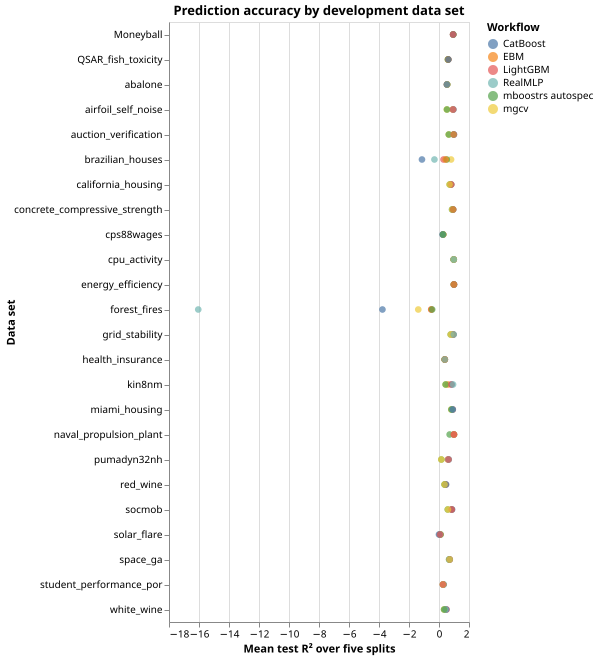

In [7]:
shown = [PRIMARY, "mgcv", "EBM", "LightGBM", "CatBoost", "RealMLP"]
plot_data = per_data.filter(pl.col("method").is_in(shown) & (pl.col("splits") == 5))
chart = alt.Chart(plot_data).mark_point(filled=True, size=45).encode(
    x=alt.X("r2:Q", title="Mean test R² over five splits"),
    y=alt.Y("dataset:N", title="Data set", sort="ascending"),
    color=alt.Color("method:N", title="Workflow"),
    tooltip=["dataset", "method", alt.Tooltip("r2:Q", format=".3f")],
).properties(title="Prediction accuracy by development data set", height=600)
display(chart)


## Interpretation and confirmation

Autospec reports the specification it evaluated, and preliminary screening
can reduce shape comparisons while adding its own fitting and prediction
cost. The [screening-mode benchmark](benchmark_preexploration.ipynb) isolates
that trade-off more directly than this multi-library comparison. The
[body-fat case](autospec_bodyfat.ipynb) demonstrates how to keep evaluation
rows outside the complete search on a real data set.

A new default policy should be fixed
before examining the reserved confirmation tasks. Report that confirmation
separately, with every planned failure and the prespecified decision rule;
selecting a policy from these same test scores and calling the result a new
validation would understate the selection cost.
